# Sizing an industry momentum portfolio

George Dharma

How much of an equal-industry portfolio should be allocated to the ten industries with the strongest lagged returns?

The 25% allocation returns 13.19% a year after costs, has 1.73% annual tracking error and limits an industry to 4.03% at rebalance. Its 95% interval for annual active return covers both −0.28 and +1.15 percentage points.

## Read or reproduce the work

The saved tables and chart can be read immediately. To execute the cells, open this notebook from the extracted Python project. Set `rebuild = True` below to regenerate the outputs from the publisher’s data. The first full run needs an internet connection. Later runs use the local copy.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image

# If the notebook was downloaded separately, unpack the Python package alongside it.
here = Path.cwd()
candidates = [here, here.parent, here / "George_Dharma_11_Equity_Python", here.parent / "George_Dharma_11_Equity_Python"]
root = next((p for p in candidates if (p / "run_analysis.py").exists() and (p / "equity").is_dir()), None)
if root is None:
    raise FileNotFoundError("Extract the complete research package and open this notebook from its project folder.")
sys.path.insert(0, str(root))
output = root / "outputs"
rebuild = False
if rebuild or not (output / "allocation_summary.csv").exists() or not (output / "allocation_risk.png").exists():
    subprocess.run([sys.executable, str(root / "run_analysis.py")], cwd=root, check=True)
print("The saved portfolio outputs are ready.")

The saved portfolio outputs are ready.


## Read the locked strategy and four portfolio sizes

The strategy was selected from validation results through 2009. The four sizing choices then use the same 192 final months. Sizing conclusions are exploratory.

In [2]:
import json
selection = json.loads((output / "selection_lock.json").read_text(encoding="utf-8"))
print("Locked strategy:", selection["selected_policy"])
results = pd.read_csv(output / "allocation_summary.csv").set_index("sleeve_weight")
chosen = ["annual_growth", "max_drawdown", "active_arithmetic", "tracking_error", "largest_target"]
results[chosen].mul(100).round(2).rename_axis("momentum share (0 to 1)")

Locked strategy: Top 10 momentum


,annual_growth,max_drawdown,active_arithmetic,tracking_error,largest_target
momentum share (0 to 1),,,,,
0.00,12.71,-25.95,0.00,0.00,2.04
0.25,13.19,-24.72,0.43,1.73,4.03
0.50,13.63,-23.49,0.86,3.46,6.02
1.00,14.42,-26.19,1.72,6.92,10.00


## Portfolio results at a glance

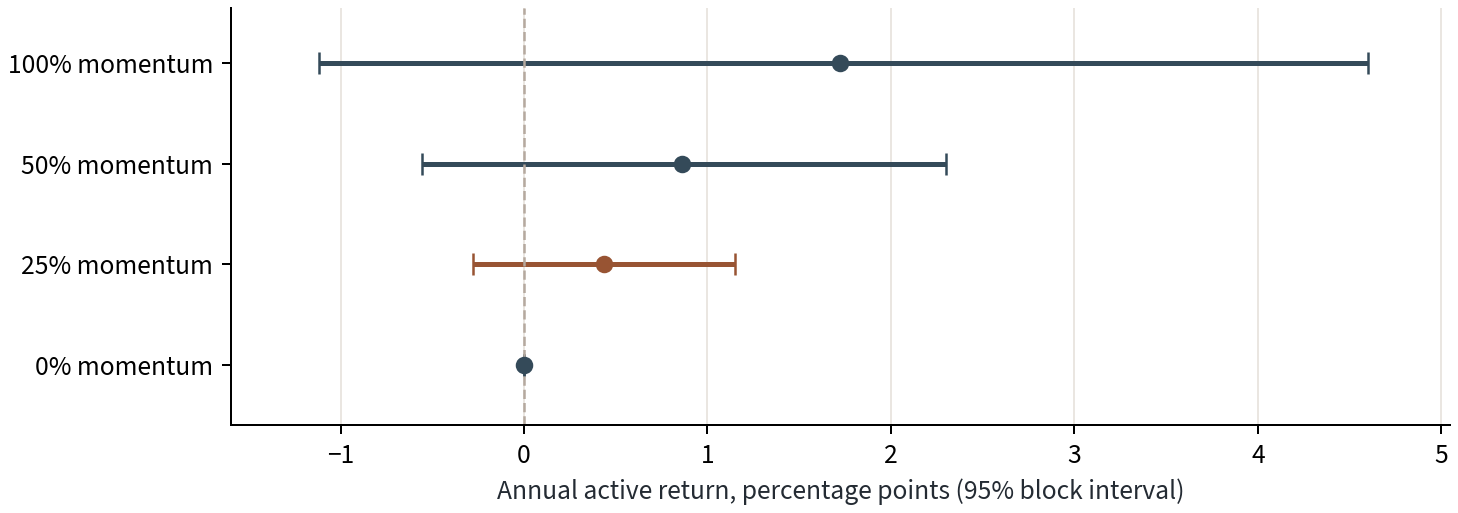

In [3]:
Image(filename=str(output / "allocation_risk.png"), width=810)

## Recalculate a mix from its monthly cash flows

Change allocation to 0, 0.25, 0.50 or 1.00. Each mix traded its own net positions and paid 10 bp for every dollar bought or sold.

In [4]:
import numpy as np
from equity.allocation import block_interval
allocation = .25
tape = pd.read_csv(output / "allocation_monthly.csv").pivot(index="month", columns="sleeve_weight", values="net")
returns = tape[allocation]
active = (returns - tape[0.]).to_numpy()
growth = (1 + returns).prod() ** (12 / len(returns)) - 1
lower, upper = block_interval(active)
print(f"Net annual growth {growth:.2%}; annual tracking error {active.std(ddof=1) * np.sqrt(12):.2%}")
print(f"Annual arithmetic active return {active.mean() * 12:.2%}; paired 95% interval [{lower:.2%}, {upper:.2%}]")
tape.tail().mul(100).round(2)

Net annual growth 13.19%; annual tracking error 1.73%
Annual arithmetic active return 0.43%; paired 95% interval [-0.28%, 1.15%]


sleeve_weight,0.00,0.25,0.50,1.00
month,,,,
2025-08,4.36,4.05,3.74,3.12
2025-09,1.55,1.96,2.38,3.21
2025-10,-0.39,-0.85,-1.31,-2.24
2025-11,1.93,1.34,0.76,-0.41
2025-12,0.63,0.77,0.91,1.19


## Locate the sources of active return

The top and bottom three industries below are annual gross contributions to the full momentum allocation relative to the equal-industry core. Trade costs enter only when converting gross performance to net performance.

In [5]:
contribution = pd.read_csv(output / "active_industries.csv")
extremes = pd.concat([contribution.head(3), contribution.tail(3)], ignore_index=True)
extremes["Annual contribution (pp)"] = (100 * extremes.annual_gross_active).round(3)
extremes[["industry", "Annual contribution (pp)"]]

,industry,Annual contribution (pp)
0,Autos,0.858
1,Fun,0.712
2,Txtls,0.574
3,PerSv,-0.213
4,Toys,-0.376
5,Mines,-0.423


## Source

Kenneth R. French Data Library, 49 US industry portfolios, US research factors and stock momentum. The source links, archive member names and published checksums are in `data/source/provenance.json`. The first full run downloads the four source archives.

[Open the original source](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_49_ind_port.html)